# Inferring $\varepsilon$-machines from stochastic simulations

- Gillespie 2A <=> A2
- MAPK
- WCM module (e.g. Thornburg)

In [4]:
using Pkg; Pkg.activate(".")

using ComputationalMechanics
using Catalyst, JumpProcesses, Plots

  Activating project at `~/.julia/dev/ComputationalMechanics/notebooks`


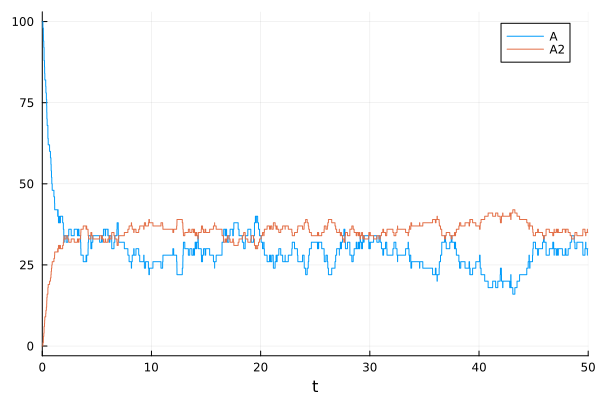

In [25]:
# simple stochastic (Gillespie) simulation of the chemical reaction 2A <=> A_2
rn = @reaction_network begin
    kf, 2A --> A2
    kr, A2 --> 2A
end

A0 = 100
u0 = [:A => A0, :A2 => 0]
p  = [:kf => 0.01, :kr => 0.1]
tspan = (0.0, 50.0)

jprob = JumpProblem(rn, u0, tspan, p)
sol   = solve(jprob, SSAStepper())
plot(sol)

In [29]:
a2_sequence = sol[:A2]
alphabet = 0:(A0 ÷ 2) 

inference = infer_machine(CSSR(), a2_sequence;
    alphabet,
    max_history=6,
    min_count=5,
    alpha = 0.001
)

ArgumentError: ArgumentError: Total probability of transitions must sum to 1, got P(1.0)